In [1]:
# Импортируем библиотеки
import pandas as pd  # Используется для загрузки, обработки и анализа данных
import numpy as np  # Используется для численных вычислений и работы с массивами

## Описание датасета CSE-CIC-IDS2018

### Источник и назначение

Датасет CSE-CIC-IDS2018 был разработан в рамках совместного проекта Communications Security Establishment (CSE) и Canadian Institute for Cybersecurity (CIC). Его основная цель — предоставить реалистичный, комплексный и воспроизводимый набор сетевых данных для разработки и тестирования систем обнаружения вторжений (Intrusion Detection Systems, IDS), в частности, для задач обнаружения аномалий и атак типа DDoS.

В отличие от статических и сильно анонимизированных наборов данных, CSE-CIC-IDS2018 построен на основе профилей пользователей и атакующих сценариев, моделирующих реальные сетевые взаимодействия в корпоративной среде с различными типами атак.

### Структура и характеристики

Датасет включает как легитимный (benign) сетевой трафик, так и различные типы атак, имитированные в контролируемой инфраструктуре. Сбор данных проводился с использованием CICFlowMeter-V3, который формирует статистические характеристики сетевых потоков (flows). Каждая запись в датасете представляет собой отдельный сетевой поток, описанный совокупностью признаков.

В исходных CSV-файлах содержится:

- Более **80 признаков**, описывающих характеристики сетевого потока.
- Информация о протоколе, портах, размере пакетов, флагах TCP, временных интервалах между пакетами и др.
- Целевая переменная (`Label`), содержащая информацию о типе трафика: "BENIGN" или одна из меток атак (например, "DDoS HOIC").

### Типы атак в датасете

Сценарии атак включают:

- Brute-force атаки (SSH, FTP)
- DoS (Denial of Service)
- DDoS (Distributed Denial of Service)
- Web-атаки (SQL Injection, XSS)
- Infiltration (внедрение изнутри)
- Botnet
- Heartbleed

В данной работе фокус сделан исключительно на **атаках типа DDoS**.

### Формат признаков

Признаки делятся на несколько групп:

- **Сетевые параметры потока**: длительность (`Flow Duration`), количество пакетов и байт в прямом и обратном направлении.
- **Размер и статистика пакетов**: минимальные, максимальные, средние значения и стандартные отклонения.
- **Временные параметры**: интервалы между пакетами (`Inter Arrival Time`), активность и простои потока.
- **Флаги TCP**: количество пакетов с флагами `SYN`, `ACK`, `FIN` и др.
- **Производительность**: объем данных и пакетов в секунду (`Flow Bytes/s`, `Flow Packets/s`).

### Целевая переменная

В рамках данной задачи, метка `Label` представляла собой либо `DDoS` — если трафик относится к DDoS-атаке, и `BENIGN` — если трафик является легитимным.

### Цель исследования

Построение алгоритма на основе метода **k-ближайших соседей (K-Nearest Neighbors, KNN)** для бинарной классификации сетевого трафика на основе признаков потоков. Модель должна демонстрировать точность классификации не ниже 70% на валидационной выборке.

В дальнейшем будет проведена предобработка данных, отбор признаков и оптимизация гиперпараметров алгоритма.

# Загрузка датасета

In [2]:
import kagglehub # Используется для загрузки датасетов напрямую с Kaggle
from kagglehub import KaggleDatasetAdapter

def load_ddos_dataset():
    """
    Загружает датасет DDoS атак с Kaggle и создаёт случайную выборку.

    Функция загружает большой датасет по частям (chunks), из каждого chunk
    берёт случайные 10% строк для уменьшения размера данных, затем сохраняет
    в локальный CSV файл.

    Returns:
        pd.DataFrame: Датафрейм с выборкой данных (примерно 10% от исходного датасета).

    Example:
        >>> df = load_ddos_dataset()
        >>> print(f"Загружено строк: {len(df)}")
        Загружено строк: 22500
    """

    # Путь к файлу внутри датасета на Kaggle
    file_path = "ddos_balanced/final_dataset.csv"

    # Размер chunk для загрузки (100,000 строк за раз)
    # Используется для экономии оперативной памяти при работе с большими файлами
    chunk_size = 100000

    # Загрузка датасета с Kaggle по частям (chunks)
    chunks = kagglehub.dataset_load(
        adapter=KaggleDatasetAdapter.PANDAS,        # adapter=PANDAS - загружаем как pandas DataFrame
        handle="devendra416/ddos-datasets",         # handle - уникальный идентификатор датасета на Kaggle (username/dataset-name)
        path=file_path,                             # path - путь к файлу внутри датасета на Kaggle
        pandas_kwargs={"chunksize": chunk_size},    # chunksize - количество строк в каждом chunk
    )

    # Список для хранения выборок из каждого chunk
    sample_list = []

    # Обработка каждого chunk
    for chunk in chunks:
        # Берём случайные 10% строк из текущего chunk
        sample = chunk.sample(
            frac=0.1,           # frac=0.1 означает 10% от данных
            random_state=42,    # random_state=42 - фиксированный seed для воспроизводимости результатов
        )
        # Добавляем выборку в список
        sample_list.append(sample)

    # Объединяем все выборки в один DataFrame
    df = pd.concat(sample_list, ignore_index=True) # ignore_index=True - создаём новый последовательный индекс (0, 1, 2, ...)

    # Сохраняем результат в CSV файл для дальнейшего использования
    df.to_csv("dataset_sampled.csv", index=False) # index=False - не сохраняем индексы как отдельную колонку

    # Возвращаем готовый датафрейм
    return df

/Users/m.babushkin/Developer/SUSU.PE/venv_3.9/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [3]:
df: pd.DataFrame
try:
    # Попытка загрузить данные из локального CSV файла
    # Если файл уже существует, используем его вместо повторной загрузки с Kaggle
    df = pd.read_csv("dataset_sampled.csv")
except FileNotFoundError:
    # Если локальный файл не найден (первый запуск или файл был удалён)
    # Загружаем датасет с Kaggle через функцию load_ddos_dataset()
    df = load_ddos_dataset()

# Информация о датасете

In [4]:
# Отображаем первые 5 строк датафрейма для ознакомления со структурой данных
df.head()

,Unnamed: 0,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22165,172.31.69.25-18.219.211.138-80-34408-6,18.219.211.138,34408,172.31.69.25,80,6,15/02/2018 07:24:59 PM,5032233,3,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,ddos
1,26628,172.31.69.25-18.219.211.138-80-40676-6,18.219.211.138,40676,172.31.69.25,80,6,15/02/2018 07:26:24 PM,10993127,3,...,0,783.0,0.0,783.0,783.0,5990709.0,0.0,5990709.0,5990709.0,ddos
2,76682,192.168.2.109-203.73.24.75-4020-80-6,192.168.2.109,4020,203.73.24.75,80,6,12/06/2010 03:12:15 PM,479425,3,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,ddos
3,23143,172.31.69.25-18.219.211.138-80-36102-6,18.219.211.138,36102,172.31.69.25,80,6,15/02/2018 07:08:53 PM,9042123,1,...,0,0.0,0.0,0.0,0.0,9042123.0,0.0,9042123.0,9042123.0,ddos
4,39435,172.31.69.25-18.219.211.138-80-44284-6,18.219.211.138,44284,172.31.69.25,80,6,15/02/2018 07:19:56 PM,1907579,1,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,ddos


In [5]:
# Выводим распределение классов в целевой колонке 'Label'
# value_counts() подсчитывает количество каждого уникального значения
print(df['Label'].value_counts())

Label
ddos      647297
Benign    632166
Name: count, dtype: int64


In [6]:
# Выводим детальную информацию о структуре датафрейма
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1279463 entries, 0 to 1279462
Data columns (total 85 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   Unnamed: 0         1279463 non-null  int64  
 1   Flow ID            1279463 non-null  object 
 2   Src IP             1279463 non-null  object 
 3   Src Port           1279463 non-null  int64  
 4   Dst IP             1279463 non-null  object 
 5   Dst Port           1279463 non-null  int64  
 6   Protocol           1279463 non-null  int64  
 7   Timestamp          1279463 non-null  object 
 8   Flow Duration      1279463 non-null  int64  
 9   Tot Fwd Pkts       1279463 non-null  int64  
 10  Tot Bwd Pkts       1279463 non-null  int64  
 11  TotLen Fwd Pkts    1279463 non-null  float64
 12  TotLen Bwd Pkts    1279463 non-null  float64
 13  Fwd Pkt Len Max    1279463 non-null  float64
 14  Fwd Pkt Len Min    1279463 non-null  float64
 15  Fwd Pkt Len Mean   1279463 non-n

# Подготовка данных в датасете

In [7]:
# Удаляем колонки, которые не несут полезной информации для обучения модели
df.drop(['Unnamed: 0', 'Flow ID', 'Src IP', 'Dst IP', 'Timestamp'], axis=1, inplace=True)

In [8]:
# Удаляем все строки, содержащие хотя бы одно пропущенное значение (NaN)
df.dropna(inplace=True)

In [9]:
# Выводим детальную информацию о структуре датафрейма
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1276490 entries, 0 to 1279462
Data columns (total 80 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   Src Port           1276490 non-null  int64  
 1   Dst Port           1276490 non-null  int64  
 2   Protocol           1276490 non-null  int64  
 3   Flow Duration      1276490 non-null  int64  
 4   Tot Fwd Pkts       1276490 non-null  int64  
 5   Tot Bwd Pkts       1276490 non-null  int64  
 6   TotLen Fwd Pkts    1276490 non-null  float64
 7   TotLen Bwd Pkts    1276490 non-null  float64
 8   Fwd Pkt Len Max    1276490 non-null  float64
 9   Fwd Pkt Len Min    1276490 non-null  float64
 10  Fwd Pkt Len Mean   1276490 non-null  float64
 11  Fwd Pkt Len Std    1276490 non-null  float64
 12  Bwd Pkt Len Max    1276490 non-null  float64
 13  Bwd Pkt Len Min    1276490 non-null  float64
 14  Bwd Pkt Len Mean   1276490 non-null  float64
 15  Bwd Pkt Len Std    1276490 non-null  

In [10]:
# Создаём булеву маску для обнаружения бесконечных значений (inf, -inf)
# select_dtypes(include=[np.number]) - выбираем только числовые колонки
# np.isinf() - возвращает True для каждой ячейки с inf/-inf значением
inf_mask = np.isinf(df.select_dtypes(include=[np.number]))

# Проверяем каждую колонку на наличие хотя бы одного inf значения
# any() - возвращает True если в колонке есть хотя бы один inf
inf_columns = inf_mask.any()

# Выводим список колонок, содержащих бесконечные значения
# inf_columns[inf_columns] - фильтруем только те колонки, где есть inf
# .index.tolist() - получаем имена колонок в виде списка
print("Columns with inf values:\n", inf_columns[inf_columns].index.tolist())

Columns with inf values:
 ['Flow Byts/s', 'Flow Pkts/s']


In [11]:
# Выводим размер датафрейма ДО обработки inf значений
# shape возвращает кортеж (количество_строк, количество_колонок)
print(f'df.shape = {df.shape}')

# Заменяем все бесконечные значения (inf и -inf) на NaN
# [np.inf, -np.inf] - список значений для замены
# np.nan - значение, на которое заменяем
# inplace=True - изменяем датафрейм напрямую
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Удаляем все строки с NaN (включая те, что были inf)
# Очищаем датасет от некорректных значений
df.dropna(inplace=True)

# Выводим размер датафрейма ПОСЛЕ обработки
print(f'non inf df.shape = {df.shape}')

df.shape = (1276490, 80)
non inf df.shape = (1274708, 80)


In [12]:
# Импортируем LabelEncoder для кодирования категориальной целевой переменной
from sklearn.preprocessing import LabelEncoder

# Название колонки с целевой переменной (класс: benign или ddos)
target_column = "Label"

# Создаём объект LabelEncoder для преобразования текстовых меток в числа
le = LabelEncoder()

# Формируем матрицу признаков X (все колонки кроме целевой)
X = df.drop(columns=[target_column])

# Формируем вектор целевой переменной y
# fit_transform() выполняет две операции:
# 1. fit() - запоминает уникальные значения ('benign', 'ddos')
# 2. transform() - преобразует их в числа (0, 1)
y = le.fit_transform(df[target_column])

# Разделение датасета на обучающую, валидационную и тестовую выборки

In [13]:
# Импортируем функцию для разделения данных на обучающую и тестовую выборки
from sklearn.model_selection import train_test_split


def train_val_test_split(X, y, train_size=0.6, val_size=0.2, test_size=0.2, random_state=42):
    """
    Разделяет данные на train, validation и test наборы с сохранением пропорций классов.

    Args:
        X (pd.DataFrame): Матрица признаков.
        y (np.ndarray): Вектор целевой переменной.
        train_size (float): Доля данных для обучения. По умолчанию 0.6 (60%).
        val_size (float): Доля данных для валидации. По умолчанию 0.2 (20%).
        test_size (float): Доля данных для тестирования. По умолчанию 0.2 (20%).
        random_state (int): Seed для воспроизводимости результатов. По умолчанию 42.

    Returns:
        tuple: (X_train, X_val, X_test, y_train, y_val, y_test)
    """

    # Проверяем, что сумма пропорций равна 1.0 (100%). Если нет - выбрасываем ошибку AssertionError
    assert train_size + val_size + test_size == 1.0

    # Отделяем test set (20% от всех данных)
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y,                       # X_temp и y_temp содержат оставшиеся 80% данных (train + val)
        test_size=test_size,
        random_state=random_state,  # random_state - фиксируем генератор случайных чисел для воспроизводимости
        stratify=y,                 # stratify=y - сохраняем пропорции классов в обеих выборках
    )

    # Вычисляем долю validation от оставшихся данных
    # val_ratio = 0.2 / (0.6 + 0.2) = 0.25
    # Это означает: из 80% данных берём 25% на validation = 20% от всего датасета
    val_ratio = val_size / (train_size + val_size)

    # Делим оставшиеся данные на train и validation
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp,             # test_size=val_ratio (0.25) означает 25% от X_temp идёт в validation. Остальные 75% от X_temp идут в train (что равно 60% от всего датасета)
        test_size=val_ratio,
        random_state=random_state,  # random_state - фиксируем генератор случайных чисел для воспроизводимости
        stratify=y_temp,            # stratify=y_temp - снова сохраняем пропорции классов
    )

    # Возвращаем все 3 набора данных
    # Train (60%) - для обучения модели
    # Val (20%) - для подбора гиперпараметров и промежуточной оценки
    # Test (20%) - для финальной оценки качества модели
    return X_train, X_val, X_test, y_train, y_val, y_test

In [14]:
# Разделяем выборку на 3 набора данных
X_train, X_val, X_test, y_train, y_val, y_test = train_val_test_split(
    X, y,
    train_size=0.6,
    val_size=0.2,
    test_size=0.2,
    random_state=42,
)

# Train (60%) - для обучения модели
print(f"Train: {len(X_train)}")

# Val (20%) - для подбора гиперпараметров и финальной оценки на "боевых" данных 
# Вообще валидационная выборка должна составляться вручную и должна быть очень маленькой, но у нас такой возможности нет
print(f"Val:   {len(X_val)}")

# Test (20%) - для оценки качества модели
print(f"Test:  {len(X_test)}")

Train: 764824
Val:   254942
Test:  254942


# Оценка корреляции признаков и облечение модели

In [15]:
# Вычисляем матрицу корреляций между всеми числовыми признаками
# corr() - вычисляет корреляцию Пирсона между всеми парами колонок
# abs() - берём абсолютные значения корреляций (игнорируем знак)
corr_matrix = X_train.corr().abs()

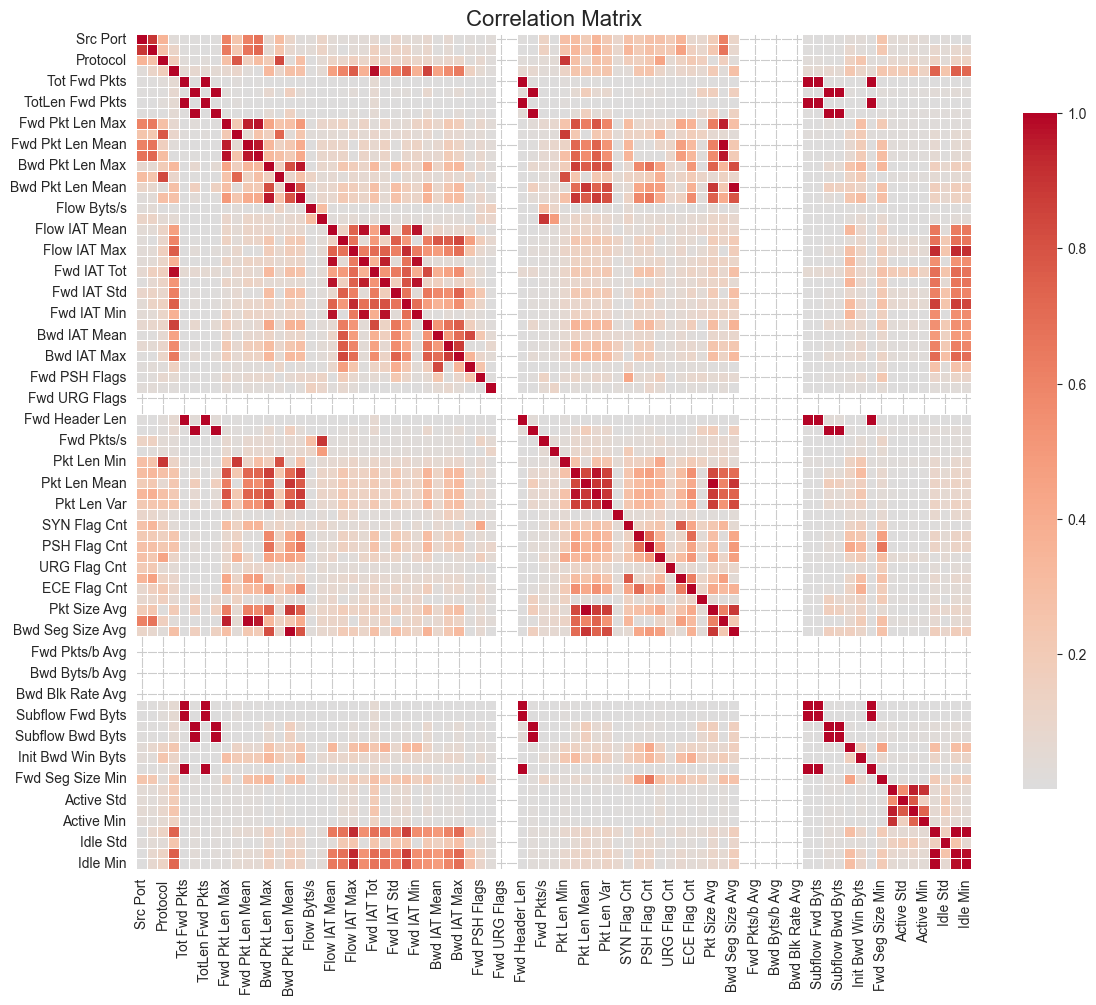

In [16]:
# Импортируем библиотеки для визуализации
import matplotlib.pyplot as plt  # Базовая библиотека для построения графиков
import seaborn as sns            # Библиотека для красивых статистических визуализаций

# Создаём фигуру (холст) размером 12x10 дюймов
plt.figure(figsize=(12, 10))

# Строим тепловую карту корреляционной матрицы
sns.heatmap(corr_matrix,
            annot=False,                # Не показывать числовые значения в ячейках (слишком много признаков)
            fmt='.2f',                  # Формат чисел - 2 знака после запятой (не используется при annot=False)
            cmap='coolwarm',            # Цветовая схема: синий (низкая корреляция) -> красный (высокая)
            center=0,                   # Центр шкалы в нуле (для симметричной палитры)
            square=True,                # Квадратные ячейки (пропорции 1:1)
            linewidths=0.5,             # Ширина линий между ячейками для разделения
            cbar_kws={"shrink": 0.8},   # Параметры цветовой шкалы (shrink - уменьшить на 20%)
)

# Добавляем заголовок графика
plt.title('Correlation Matrix', fontsize=16)

# Автоматически подгоняем размеры элементов, чтобы всё поместилось
plt.tight_layout()

# Отображаем график
plt.show()

In [17]:
# Создаём верхний треугольник корреляционной матрицы для избежания дублирования пар
# np.triu() - создаёт верхнюю треугольную матрицу (upper triangle)
# k=1 - начинаем с 1-й диагонали (исключаем главную диагональ, где корреляция = 1)
# astype(bool) - преобразуем в булеву маску (True/False)
# where() - оставляем значения только там, где маска True, остальное заменяется на NaN
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Находим признаки для удаления
# any() - возвращает True если хотя бы одно условие выполнено
to_drop = [column for column in upper.columns if any(upper[column] > 0.7)]

# Выводим количество признаков, которые будут удалены
print(f"Removing {len(to_drop)} correlated features (>0.7)")

# Удаляем высококоррелированные признаки из матрицы
X_train.drop(columns=to_drop, inplace=True)
X_val.drop(columns=to_drop, inplace=True)
X_test.drop(columns=to_drop, inplace=True)

# Выводим количество оставшихся признаков после фильтрации
print(f"Deleted columns: {to_drop}")
print(f"Remained features: {X_train.shape[1]}") # shape[1] - количество колонок (признаков)

Removing 44 correlated features (>0.7)
Deleted columns: ['Dst Port', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var', 'CWE Flag Count', 'ECE Flag Cnt', 'Pkt Size Avg', 'Fwd Seg Size Avg', 'Bwd Seg Size Avg', 'Subflow Fwd Pkts', 'Subflow Fwd Byts', 'Subflow Bwd Pkts', 'Subflow Bwd Byts', 'Fwd Act Data Pkts', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Max', 'Idle Min']
Remained features: 35


In [18]:
# Вычисляем матрицу корреляций между всеми числовыми признаками
# corr() - вычисляет корреляцию Пирсона между всеми парами колонок
# abs() - берём абсолютные значения корреляций (игнорируем знак)
corr_matrix = X_train.corr().abs()

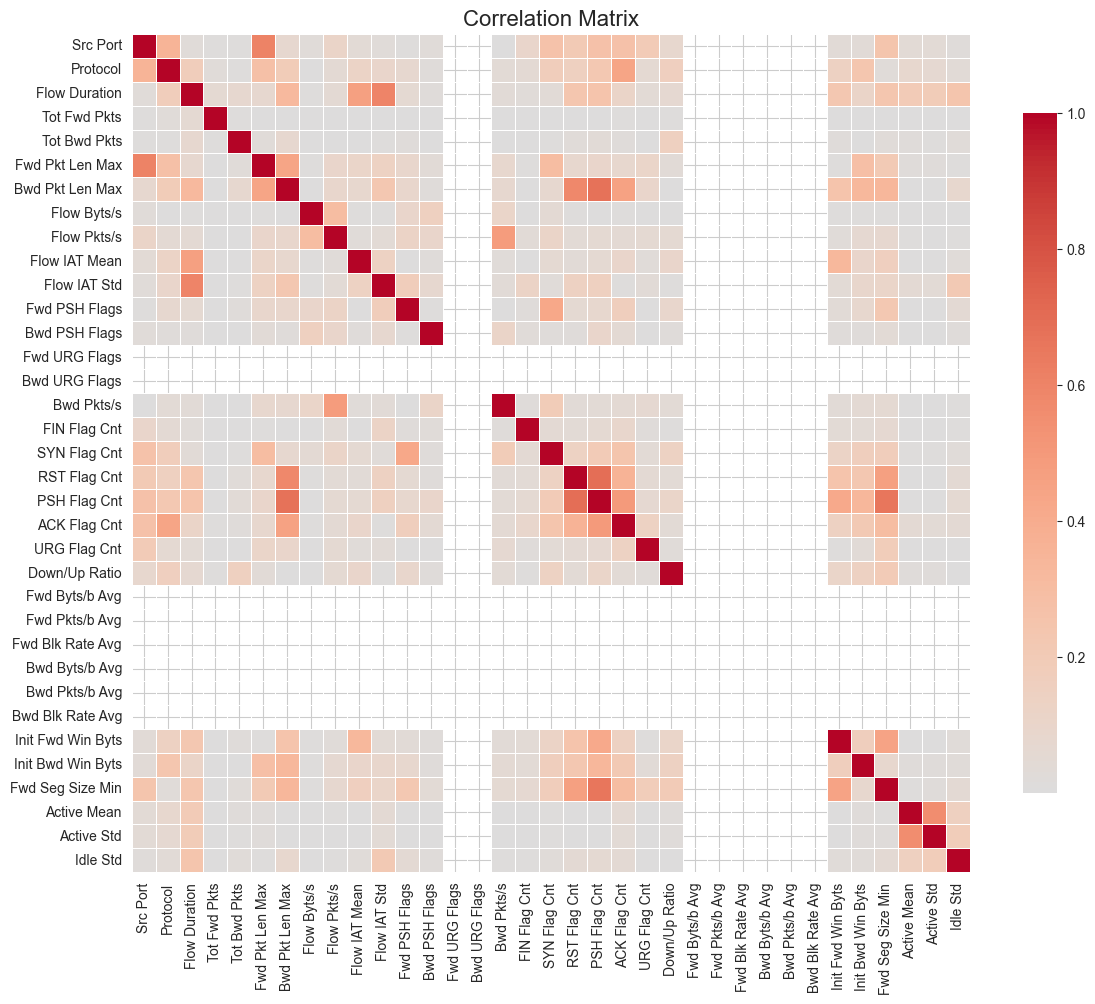

In [19]:
# Импортируем библиотеки для визуализации
import matplotlib.pyplot as plt  # Базовая библиотека для построения графиков
import seaborn as sns            # Библиотека для красивых статистических визуализаций

# Создаём фигуру (холст) размером 12x10 дюймов
plt.figure(figsize=(12, 10))

# Строим тепловую карту корреляционной матрицы
sns.heatmap(corr_matrix,
            annot=False,                # Не показывать числовые значения в ячейках (слишком много признаков)
            fmt='.2f',                  # Формат чисел - 2 знака после запятой (не используется при annot=False)
            cmap='coolwarm',            # Цветовая схема: синий (низкая корреляция) -> красный (высокая)
            center=0,                   # Центр шкалы в нуле (для симметричной палитры)
            square=True,                # Квадратные ячейки (пропорции 1:1)
            linewidths=0.5,             # Ширина линий между ячейками для разделения
            cbar_kws={"shrink": 0.8},   # Параметры цветовой шкалы (shrink - уменьшить на 20%)
)

# Добавляем заголовок графика
plt.title('Correlation Matrix', fontsize=16)

# Автоматически подгоняем размеры элементов, чтобы всё поместилось
plt.tight_layout()

# Отображаем график
plt.show()

# Подбор гиперпараметров

In [20]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Создание конвейера (pipeline) для последовательной обработки данных
pipeline = Pipeline([
    # Этап 1: Стандартизация признаков (приведение к нулевому среднему и единичной дисперсии)
    # Необходима для корректной работы PCA и KNN
    ('scaler', StandardScaler()),

    # Этап 2: Снижение размерности с помощью метода главных компонент (PCA)
    # Уменьшает количество признаков, сохраняя максимум информации
    ('pca', PCA()),

    # Этап 3: Классификатор методом k ближайших соседей
    # Финальный алгоритм классификации
    ('knn', KNeighborsClassifier())
])

# Словарь с параметрами для перебора (поиска оптимальных значений)
param_grid = {
    # Количество главных компонент для PCA (сколько признаков оставить)
    'pca__n_components': [10, 20, 30],

    # Количество соседей для KNN (сколько ближайших точек учитывать)
    'knn__n_neighbors': [3, 5, 7, 9, 11],

    # Способ взвешивания соседей:
    # 'uniform' - все соседи имеют одинаковый вес
    # 'distance' - вес обратно пропорционален расстоянию
    'knn__weights': ['uniform', 'distance']
}

# Создание объекта для поиска оптимальных гиперпараметров по сетке
# Всего будет проверено 3 × 5 × 2 = 30 комбинаций параметров
grid_search = GridSearchCV(
    pipeline,              # Конвейер для оптимизации
    param_grid,            # Сетка параметров для перебора
    cv=3,                  # Количество блоков для кросс-валидации (3-fold CV)
    scoring='accuracy',    # Метрика оптимизации (accuracy)
    n_jobs=-1,             # Использовать все доступные процессоры для ускорения
    verbose=2,             # Уровень детализации вывода (2 = подробный)
)

In [21]:
# Обучаем Grid Search
grid_search.fit(X_val, y_val)

Fitting 3 folds for each of 30 candidates, totalling 90 fits


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('pca', PCA()),
                                       ('knn', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'knn__n_neighbors': [3, 5, 7, 9, 11],
                         'knn__weights': ['uniform', 'distance'],
                         'pca__n_components': [10, 20, 30]},
             scoring='accuracy', verbose=2)

In [22]:
print(f"Best parameteres: {grid_search.best_params_}")
print(f"Best CV score: {grid_search.best_score_:.4f}")

Best parameteres: {'knn__n_neighbors': 3, 'knn__weights': 'distance', 'pca__n_components': 30}
Best CV score: 0.9983


# kNN модель

In [23]:
# Строим модель по наилучшим параметрам с предыдущего шага
model = Pipeline([
    # Этап 1: Стандартизация признаков (приведение к нулевому среднему и единичной дисперсии)
    # Необходима для корректной работы PCA и KNN
    ('scaler', StandardScaler()),

    # Этап 2: Снижение размерности с помощью метода главных компонент (PCA)
    # Уменьшает количество признаков, сохраняя максимум информации
    ('pca', PCA(n_components=30)),

    # Этап 3: Классификатор методом k ближайших соседей
    # Финальный алгоритм классификации
    ('knn', KNeighborsClassifier(n_neighbors=3, weights='distance'))
])

In [24]:
# Обучаем модель
model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('pca', PCA(n_components=30)),
                ('knn',
                 KNeighborsClassifier(n_neighbors=3, weights='distance'))])

# Проверка на тестовых данных

In [25]:
# Предсказываем значения на тестовой выборке
y_test_pred = model.predict(X_test)

In [26]:
# Импорт функции для создания подробного отчёта о качестве классификации
from sklearn.metrics import classification_report

# Вывод подробного отчёта о классификации
# classification_report() создаёт таблицу с метриками качества для каждого класса:
#
# Параметры:
#   y_test - истинные метки классов (правильные ответы)
#   y_test_pred - предсказанные моделью метки классов
#   digits=4 - количество знаков после запятой для отображения метрик
#
# Отчёт включает для каждого класса:
#   - precision (точность) - доля правильных среди предсказанных как этот класс
#   - recall (полнота) - доля найденных объектов класса среди всех объектов класса
#   - f1-score - гармоническое среднее между precision и recall
#   - support - количество объектов данного класса в тестовой выборке
#
# Также показывает общие метрики:
#   - accuracy - общая точность модели
#   - macro avg - простое среднее метрик по всем классам
#   - weighted avg - взвешенное среднее (учитывает количество объектов каждого класса)
print(classification_report(y_test, y_test_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9994    0.9982    0.9988    125483
           1     0.9983    0.9994    0.9989    129459

    accuracy                         0.9988    254942
   macro avg     0.9988    0.9988    0.9988    254942
weighted avg     0.9988    0.9988    0.9988    254942



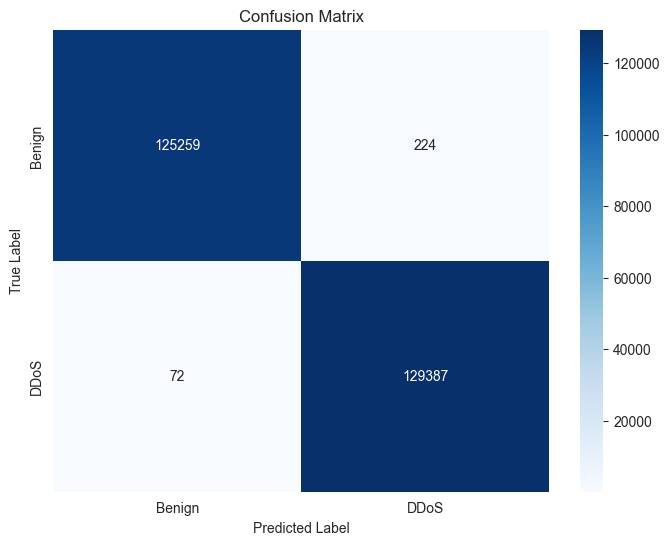

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns # библиотека для отображения красивых графиков
import matplotlib.pyplot as plt

# Вычисление матрицы ошибок
cm = confusion_matrix(y_test, y_test_pred)

# Создание графика
plt.figure(figsize=(8, 6))

# Построение тепловой карты
sns.heatmap(
    cm,
    annot=True,                      # Показывать значения в ячейках
    fmt='d',                         # Формат: целые числа
    cmap='Blues',                    # Цветовая палитра: синие оттенки
    xticklabels=['Benign', 'DDoS'],  # Метки столбцов (что предсказала модель)
    yticklabels=['Benign', 'DDoS'],  # Метки строк (что на самом деле)
)

# Настройка заголовков и подписей осей
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# Отображение графика
plt.show()

# Проверка на валидационных данных

In [28]:
# Предсказываем значения на валидационной выборке
y_val_pred = model.predict(X_val)

In [29]:
# Вывод подробного отчёта о классификации
# classification_report() создаёт таблицу с метриками качества для каждого класса:
#
# Параметры:
#   y_val - истинные метки классов (правильные ответы)
#   y_val_pred - предсказанные моделью метки классов
#   digits=4 - количество знаков после запятой для отображения метрик
#
# Отчёт включает для каждого класса:
#   - precision (точность) - доля правильных среди предсказанных как этот класс
#   - recall (полнота) - доля найденных объектов класса среди всех объектов класса
#   - f1-score - гармоническое среднее между precision и recall
#   - support - количество объектов данного класса в тестовой выборке
#
# Также показывает общие метрики:
#   - accuracy - общая точность модели
#   - macro avg - простое среднее метрик по всем классам
#   - weighted avg - взвешенное среднее (учитывает количество объектов каждого класса)
print(classification_report(y_val, y_val_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9993    0.9983    0.9988    125483
           1     0.9984    0.9993    0.9989    129459

    accuracy                         0.9989    254942
   macro avg     0.9989    0.9988    0.9989    254942
weighted avg     0.9989    0.9989    0.9989    254942



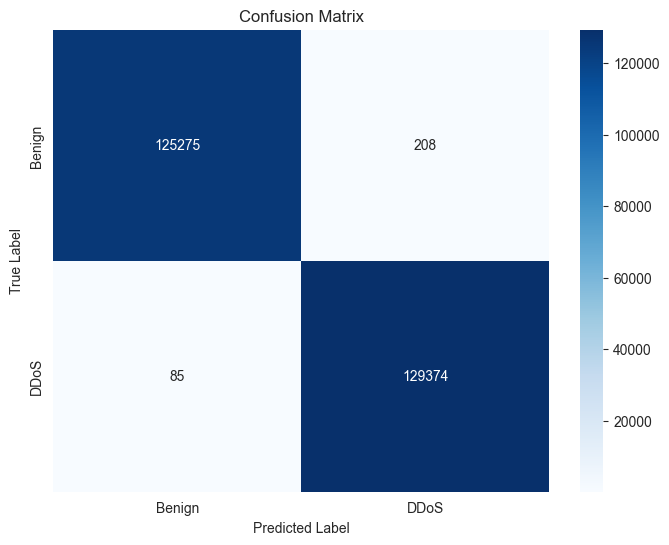

In [30]:
from sklearn.metrics import confusion_matrix
import seaborn as sns # библиотека для отображения красивых графиков
import matplotlib.pyplot as plt

# Вычисление матрицы ошибок
cm = confusion_matrix(y_val, y_val_pred)

# Создание графика
plt.figure(figsize=(8, 6))

# Построение тепловой карты
sns.heatmap(
    cm,
    annot=True,                      # Показывать значения в ячейках
    fmt='d',                         # Формат: целые числа
    cmap='Blues',                    # Цветовая палитра: синие оттенки
    xticklabels=['Benign', 'DDoS'],  # Метки столбцов (что предсказала модель)
    yticklabels=['Benign', 'DDoS'],  # Метки строк (что на самом деле)
)

# Настройка заголовков и подписей осей
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# Отображение графика
plt.show()